# 무작위 모양 복원 → seed별 이미지 분류 성능

- **데이터**: `data/steel_plates_faults.csv` (원본)
- **분할**: `data/test_index.csv` (class_split 노트북의 stratified 20% test) 그대로 사용
- **목적**: `원우_shape_visualization`의 점대칭 렌더러를 **무작위 렌더러**로 바꾸고, `random_state`(seed)마다 그린 이미지로 분류 모델을 학습해서 **가장 좋은 seed의 결과**를 본다.

## 진행 순서

| 단계 | 사용하는 데이터 |
|---|---|
| ① seed마다 전체 결함을 무작위로 그림 | (그리기만 함, 학습 없음) |
| ② seed마다 이미지 → RandomForest, **train 5-fold CV** Macro F1 | train만 |
| ③ CV 1등 seed 선택 | train만 |
| ④ 선택한 seed 하나로 **test 평가 (한 번)** | test |
| ⑤ 참고: 모든 seed의 test 점수, seed 평균(앙상블) | test — **선택에 쓰지 않음** |

> seed는 클래스와 상관없는 노이즈만 바꾼다. 그래서 CV 1등 seed라도 test에서는 평범할 가능성이 높다 (winner's curse). ⑤는 그걸 눈으로 확인하는 용도.

## 이미지에 담기는 정보

- 모양을 정하는 입력은 `W`, `H`, `Pixels_Areas`, `X_Perimeter`, `Y_Perimeter` 5개뿐.
- 긴 변을 96px로 정규화하므로 **절대 크기는 사라짐** (가로세로 비율·fill·rx·ry만 남음).
- 밝기·두께 등 나머지 특성은 이미지에 없음 → 원본 27개 특성 RF(CV Macro F1 ≈ 0.79)보다 낮게 나오는 게 정상.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import ndimage
from joblib import Parallel, delayed

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

RANDOM_STATE = 42

## 1. 데이터 로드 & 모양 정보 계산

In [2]:
raw = pd.read_csv("data/steel_plates_faults.csv")
FAULTS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains", "Dirtiness", "Bumps", "Other_Faults"]

shape = pd.DataFrame({
    "W":    raw["X_Maximum"] - raw["X_Minimum"],
    "H":    raw["Y_Maximum"] - raw["Y_Minimum"],
    "area": raw["Pixels_Areas"],
    "px":   raw["X_Perimeter"],
    "py":   raw["Y_Perimeter"],
    "Fault": raw[FAULTS].idxmax(axis=1),
})
shape["fill"] = shape["area"] / (shape["W"] * shape["H"])
shape["rx"]   = shape["px"] / shape["W"]
shape["ry"]   = shape["py"] / shape["H"]

test_idx = pd.read_csv("data/test_index.csv")["test_index"]
is_train = ~shape.index.isin(test_idx)
y = shape["Fault"]
y_train, y_test = y[is_train], y[~is_train]

print("train:", is_train.sum(), "/ test:", (~is_train).sum())

train: 1552 / test: 389


## 2. 무작위 렌더러

점대칭 버전(`원우_shape_visualization`)과 같은 틀(superellipse + 경계 출렁임 + 이분 탐색)을 쓰되, 아래를 **seed로 무작위**하게 정한다.

| 무작위 요소 | 효과 |
|---|---|
| 중심 위치 `cu`, `cv` | 가장 넓은 행·열이 가운데가 아닌 곳에 생김 → 위아래·좌우 비대칭 |
| 변마다 출렁임 크기 `sL, sR, sT, sB` | 왼쪽은 많이, 오른쪽은 조금 꼬불꼬불 같은 차이 |
| 변마다 출렁임 간격 `gL, gR, gT, gB` | 마주 보는 변의 출렁임 위치가 어긋남 |

**전제 조건은 그대로 맞춘다**

- 박스 네 변에 닿기: 중심 행·열을 픽셀 중심에 맞춰서(`snap`) 그 행·열은 항상 박스 끝까지 채워짐
- 넓이 = `Pixels_Areas`, 둘레 = `X_Perimeter`, `Y_Perimeter`: 무작위 모양을 정한 **뒤에** 출렁임 폭과 `p`를 이분 탐색으로 맞춤
- 한 덩어리: 중심과 연결된 부분만 남김

In [3]:
CANVAS = 96      # 긴 변 픽셀 수
MIN_SIDE = 16    # 짧은 변 최소 픽셀 수
N_ITER = 3       # 둘레 ↔ 넓이 번갈아 맞추는 횟수


def canvas_size(W, H):
    s = CANVAS / max(W, H)
    return max(MIN_SIDE, round(W * s)), max(MIN_SIDE, round(H * s))


def snap(c, n):
    # 중심 c를 가장 가까운 픽셀 중심으로 맞춤 → 그 행/열이 정확히 0이 되어 박스 끝까지 닿음
    return (np.clip(np.round((c + 1) / 2 * n - 0.5), 0, n - 1) + 0.5) / n * 2 - 1


def warp(t, c):
    # [-1, 1] 좌표를 c 위치가 0이 되도록 비대칭으로 늘림 (양 끝 ±1은 그대로)
    return np.where(t < c, (t - c) / (1 + c), (t - c) / (1 - c))


def bump(t, k, g):
    # t=0에서 0, 바깥으로 k번 출렁이는 0~1 함수. g로 출렁임 간격을 변마다 다르게
    return (1 - np.cos(k * np.pi * np.abs(t) ** g)) / 2


def random_style(rng):
    return dict(cu=rng.uniform(-0.5, 0.5), cv=rng.uniform(-0.5, 0.5),
                sL=rng.uniform(0.4, 1), sR=rng.uniform(0.4, 1),
                sT=rng.uniform(0.4, 1), sB=rng.uniform(0.4, 1),
                gL=rng.uniform(0.7, 1.4), gR=rng.uniform(0.7, 1.4),
                gT=rng.uniform(0.7, 1.4), gB=rng.uniform(0.7, 1.4))


def render(w, h, p, ax, kx, ay, ky, st):
    u = (np.arange(w) + 0.5) / w * 2 - 1
    v = (np.arange(h) + 0.5) / h * 2 - 1
    cu, cv = snap(st["cu"], w), snap(st["cv"], h)
    U, V = np.meshgrid(warp(u, cu), warp(v, cv))
    m = np.abs(U) ** p + np.abs(V) ** p <= 1                    # 넓이 담당
    m &= U >= -1 + ax * st["sL"] * bump(V, kx, st["gL"])       # 왼쪽 경계 출렁임
    m &= U <=  1 - ax * st["sR"] * bump(V, kx, st["gR"])       # 오른쪽
    m &= V >= -1 + ay * st["sT"] * bump(U, ky, st["gT"])       # 위쪽
    m &= V <=  1 - ay * st["sB"] * bump(U, ky, st["gB"])       # 아래쪽
    lab, _ = ndimage.label(m)
    cy, cx = np.argmin(np.abs(V[:, 0])), np.argmin(np.abs(U[0]))
    return lab == lab[cy, cx]                                   # 중심과 연결된 한 덩어리만


def measure(m):
    pad = np.pad(m.astype(int), 1)
    lh = np.abs(np.diff(pad, axis=0)).sum()   # 가로 경계 길이 (위+아래)
    lv = np.abs(np.diff(pad, axis=1)).sum()   # 세로 경계 길이 (좌+우)
    return m.sum(), lh / 2, lv / 2


def bisect(f, lo, hi, target, n=18):
    for _ in range(n):
        mid = (lo + hi) / 2
        if f(mid) < target:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


def fit_shape(W, H, area, px, py, rng, max_amp=0.8, max_k=30):
    w, h = canvas_size(W, H)
    t_fill = area / (W * H)
    t_px = min(px / W, w / 2) * w
    t_py = min(py / H, h / 2) * h
    prm = dict(p=2.0, ax=0.0, kx=1, ay=0.0, ky=1, st=random_style(rng))   # 모양 스타일은 먼저 무작위로 고정

    for _ in range(N_ITER):
        for amp, k, idx, target in (("ax", "kx", 1, t_px), ("ay", "ky", 2, t_py)):
            for kk in range(1, max_k + 1):
                g = lambda a: measure(render(w, h, **{**prm, amp: a, k: kk}))[idx]
                if g(max_amp) >= target or kk == max_k:
                    prm[k] = kk
                    prm[amp] = bisect(g, 0, max_amp, target, 12)
                    break
        f = lambda lp: render(w, h, **{**prm, "p": np.exp(lp)}).sum()
        prm["p"] = np.exp(bisect(f, np.log(0.15), np.log(30), t_fill * w * h))

    m = render(w, h, **prm)
    a, mx, my = measure(m)
    fit = {"fill": (t_fill, a / (w * h)), "rx": (px / W, mx / w), "ry": (py / H, my / h)}
    return m, prm, fit


def render_one(r, seed, i):
    # 샘플마다 (seed, 행 번호)로 난수 생성 → seed가 같으면 언제 돌려도 같은 그림
    return fit_shape(r.W, r.H, r.area, r.px, r.py, np.random.default_rng([seed, i]))

## 3. 샘플 하나를 seed만 바꿔서 그려 보기

같은 결함, 같은 전제 조건인데 seed마다 모양만 다르다. 아래 표에서 목표값과 복원값이 seed와 상관없이 맞는지 확인.

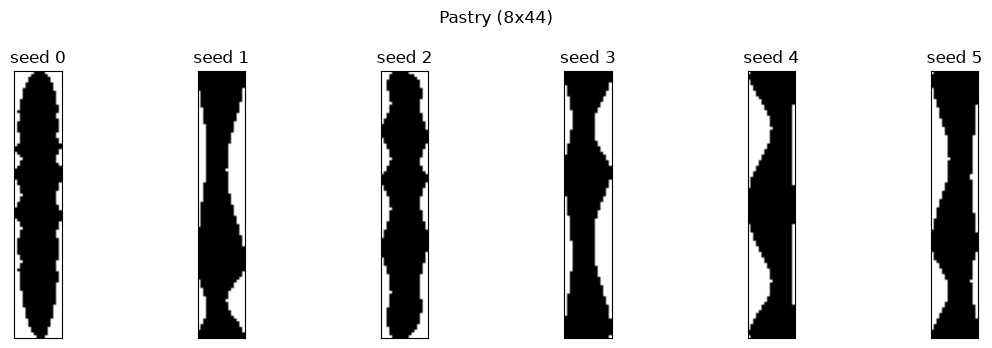

,fill_target,rx_target,ry_target,fill_got,rx_got,ry_got
seed,,,,,,
0,0.759,2.125,1.0,0.759,2.176,1.0
1,0.759,2.125,1.0,0.722,2.176,1.0
2,0.759,2.125,1.0,0.758,2.176,1.0
3,0.759,2.125,1.0,0.725,2.059,1.0
4,0.759,2.125,1.0,0.732,2.176,1.0
5,0.759,2.125,1.0,0.740,2.118,1.0


In [4]:
i = int(shape.index[is_train][0])
r = shape.loc[i]

fig, axes = plt.subplots(1, 6, figsize=(12, 3.5))
rows = []
for ax, seed in zip(axes, range(6)):
    m, _, fit = render_one(r, seed, i)
    ax.imshow(m, cmap="gray_r")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"seed {seed}")
    rows.append({"seed": seed} | {f"{k}_target": t for k, (t, _) in fit.items()}
                               | {f"{k}_got": got for k, (_, got) in fit.items()})
plt.suptitle(f"{r.Fault} ({r.W}x{r.H})")
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("seed").round(3)

## 4. 이미지 → 모델 입력

- 모양마다 캔버스 크기가 다르므로 **96×96 가운데에 패딩** (가로세로 비율은 유지)
- 3×3 블록 평균으로 **32×32**로 줄여서 1,024차원 벡터로 사용
- 전체 1,941개를 seed마다 다시 그리므로, 한 번 그린 결과는 `output/random_render/`에 저장해 두고 재사용

In [5]:
POOL = 3                                  # 96 / 3 = 32
CACHE = Path("output/random_render")
CACHE.mkdir(parents=True, exist_ok=True)


def to_vector(m):
    h, w = m.shape
    img = np.zeros((CANVAS, CANVAS), dtype=np.float32)
    top, left = (CANVAS - h) // 2, (CANVAS - w) // 2
    img[top:top + h, left:left + w] = m
    small = img.reshape(CANVAS // POOL, POOL, CANVAS // POOL, POOL).mean(axis=(1, 3))
    return small.ravel()


def render_all(seed):
    path = CACHE / f"seed_{seed}.npy"
    if path.exists():
        return np.load(path)
    masks = Parallel(n_jobs=-1)(delayed(render_one)(r, seed, i) for i, r in shape.iterrows())
    X = np.stack([to_vector(m) for m, _, _ in masks])
    np.save(path, X)
    return X

## 5. seed별 train 5-fold CV

- 모델은 `RandomForestClassifier` (`random_state` 고정) → 점수 차이는 **렌더링 seed 차이에서만** 생긴다
- 처음 실행할 때 seed 하나당 그리는 데 10~20초 정도 (CPU 코어 수에 따라 다름). 두 번째부터는 캐시를 읽음
- 각 seed의 OOF 확률도 저장해서, 뒤에서 **seed 평균(앙상블)** CV 점수도 계산

In [6]:
SEEDS = range(20)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def make_model():
    return RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)


X_by_seed, oof_by_seed, cv_rows = {}, {}, []
for seed in SEEDS:
    X = render_all(seed)
    X_by_seed[seed] = X
    oof = cross_val_predict(make_model(), X[is_train], y_train, cv=cv, method="predict_proba")
    oof_by_seed[seed] = oof
    pred = np.array(sorted(FAULTS))[oof.argmax(axis=1)]
    cv_rows.append({"seed": seed,
                    "cv_accuracy": accuracy_score(y_train, pred),
                    "cv_f1_macro": f1_score(y_train, pred, average="macro")})
    print(f"seed {seed:2d}  CV Macro F1 {cv_rows[-1]['cv_f1_macro']:.4f}")

cv_result = pd.DataFrame(cv_rows).set_index("seed")
cv_result.describe().round(4)

seed  0  CV Macro F1 0.3503
seed  1  CV Macro F1 0.3298
seed  2  CV Macro F1 0.3454
seed  3  CV Macro F1 0.3426
seed  4  CV Macro F1 0.3537
seed  5  CV Macro F1 0.3480
seed  6  CV Macro F1 0.3444
seed  7  CV Macro F1 0.3308
seed  8  CV Macro F1 0.3516
seed  9  CV Macro F1 0.3388
seed 10  CV Macro F1 0.3258
seed 11  CV Macro F1 0.3490
seed 12  CV Macro F1 0.3465
seed 13  CV Macro F1 0.3276
seed 14  CV Macro F1 0.3056
seed 15  CV Macro F1 0.3637
seed 16  CV Macro F1 0.3312
seed 17  CV Macro F1 0.3459
seed 18  CV Macro F1 0.3348
seed 19  CV Macro F1 0.3415


,cv_accuracy,cv_f1_macro
count,20.0000,20.0000
mean,0.4996,0.3404
std,0.0078,0.0128
min,0.4832,0.3056
25%,0.4965,0.3311
50%,0.4994,0.3435
75%,0.5039,0.3482
max,0.5174,0.3637


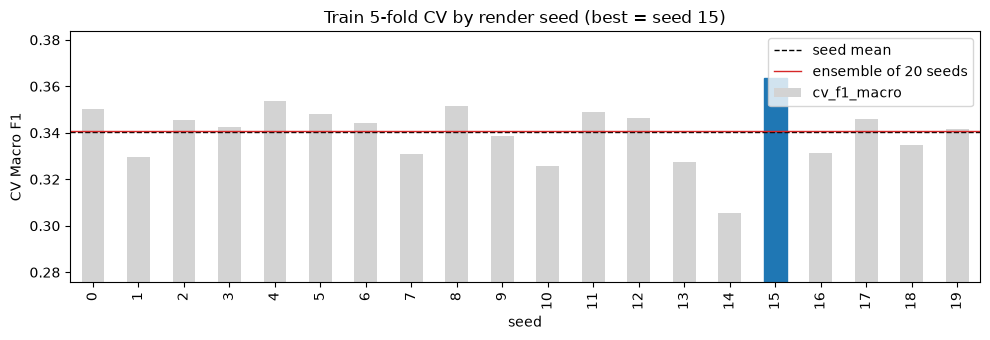

best seed 15: CV Macro F1 0.3637
seed 평균:            0.3404 ± 0.0128
seed 20개 앙상블:      0.3410


In [7]:
CLASSES = np.array(sorted(FAULTS))   # RandomForest의 classes_ 순서 (알파벳)
best_seed = int(cv_result["cv_f1_macro"].idxmax())

oof_mean = np.mean([oof_by_seed[s] for s in SEEDS], axis=0)
ens_cv_f1 = f1_score(y_train, CLASSES[oof_mean.argmax(axis=1)], average="macro")

ax = cv_result["cv_f1_macro"].plot(kind="bar", figsize=(10, 3.5), color="lightgray")
ax.patches[list(SEEDS).index(best_seed)].set_color("tab:blue")
ax.axhline(cv_result["cv_f1_macro"].mean(), color="k", ls="--", lw=1, label="seed mean")
ax.axhline(ens_cv_f1, color="tab:red", ls="-", lw=1, label=f"ensemble of {len(SEEDS)} seeds")
ax.set_ylim(cv_result["cv_f1_macro"].min() - 0.03, max(cv_result["cv_f1_macro"].max(), ens_cv_f1) + 0.02)
ax.set_ylabel("CV Macro F1")
ax.set_title(f"Train 5-fold CV by render seed (best = seed {best_seed})")
ax.legend()
plt.tight_layout()
plt.show()

print(f"best seed {best_seed}: CV Macro F1 {cv_result.loc[best_seed, 'cv_f1_macro']:.4f}")
print(f"seed 평균:            {cv_result['cv_f1_macro'].mean():.4f} ± {cv_result['cv_f1_macro'].std():.4f}")
print(f"seed {len(SEEDS)}개 앙상블:      {ens_cv_f1:.4f}")

## 6. best seed로 그린 결함 갤러리 (train 샘플)

클래스마다 무작위 6개. 제목: 실제 크기(W×H), fill / rx / ry 목표값.

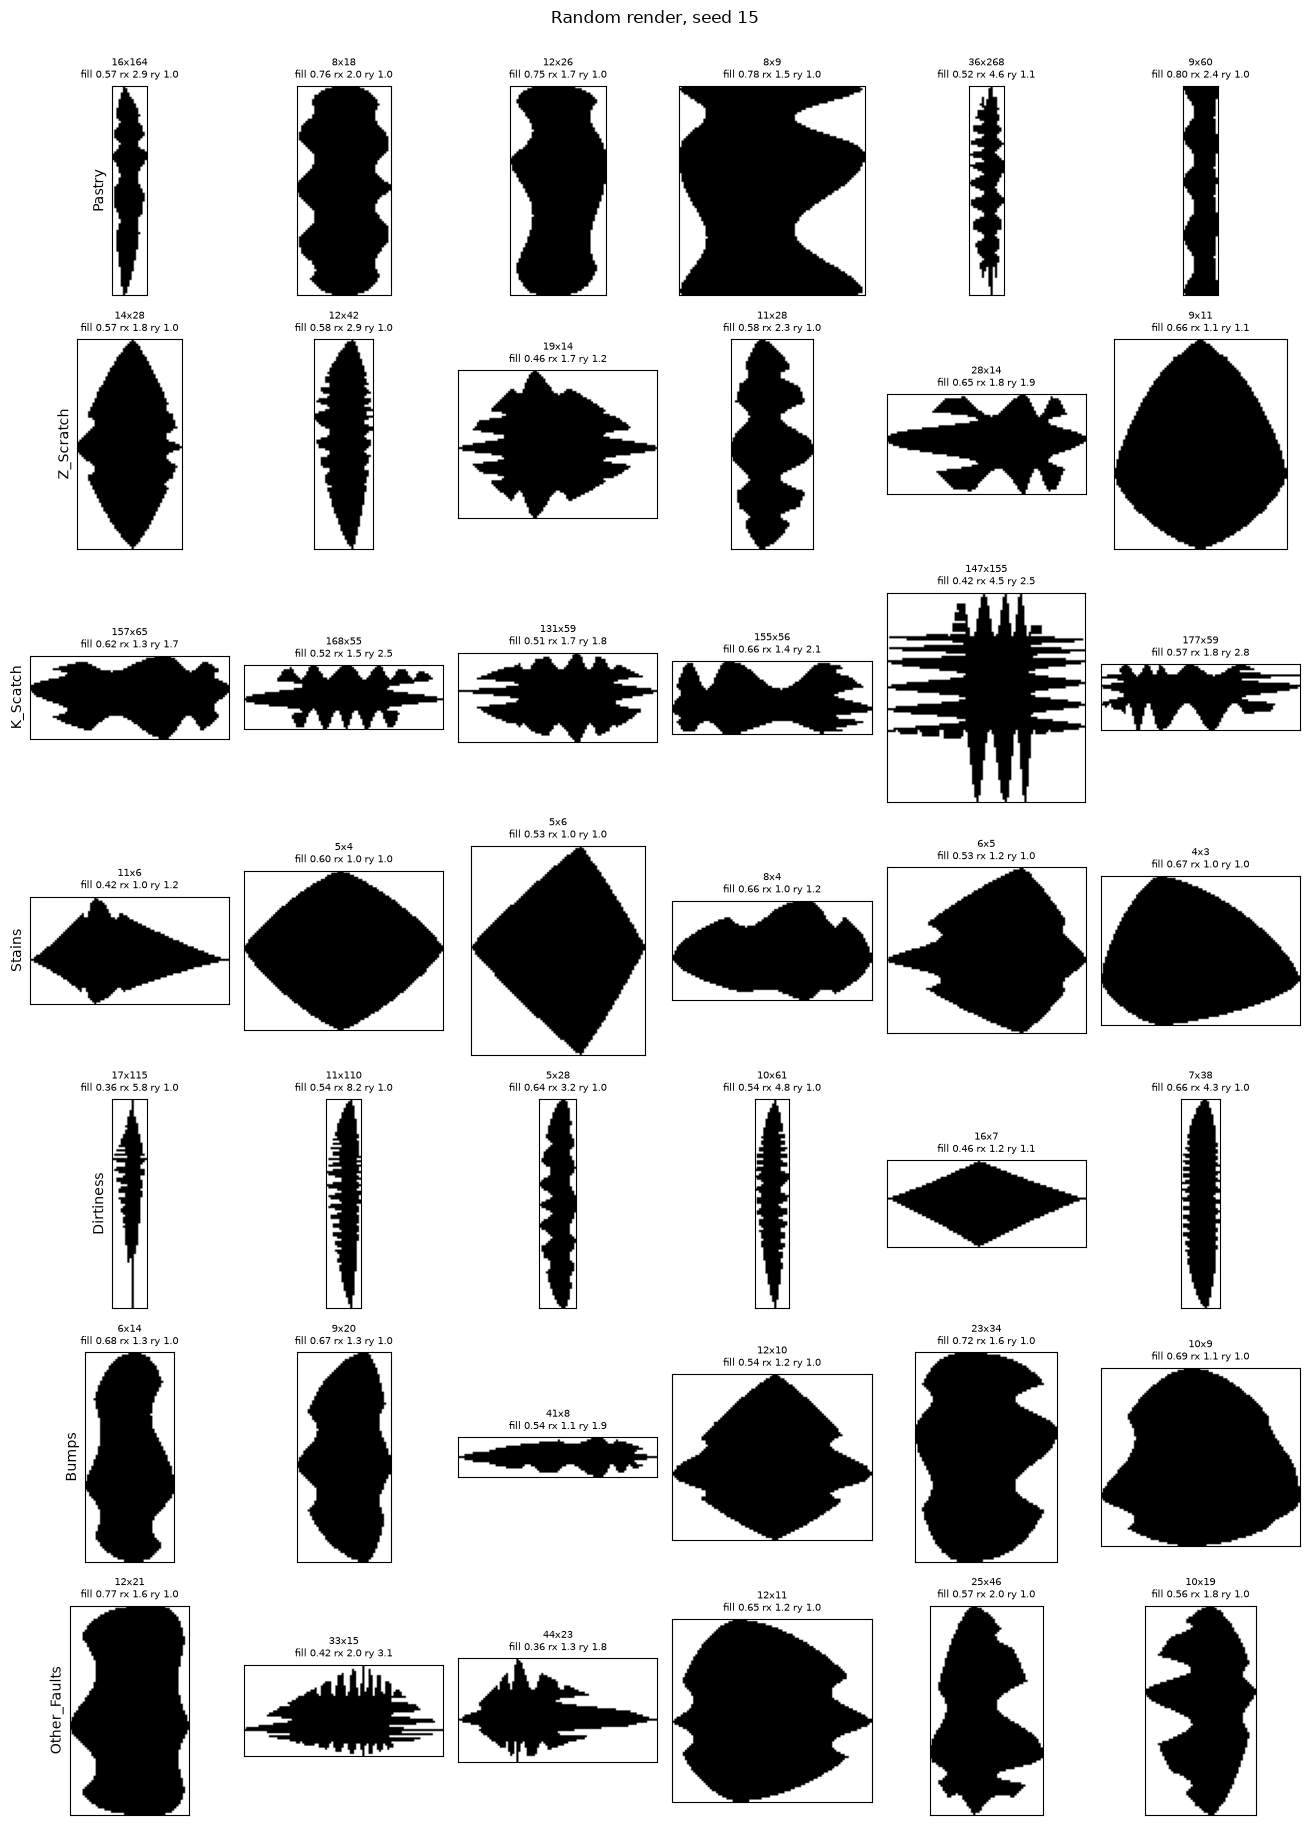

In [8]:
N_PER_CLASS = 6
samples = shape[is_train].groupby("Fault").sample(N_PER_CLASS, random_state=0)

fig, axes = plt.subplots(len(FAULTS), N_PER_CLASS, figsize=(2.2 * N_PER_CLASS, 2.6 * len(FAULTS)))
for row, fault in enumerate(FAULTS):
    for col, (i, r) in enumerate(samples[samples["Fault"] == fault].iterrows()):
        m, _, _ = render_one(r, best_seed, i)
        ax = axes[row, col]
        ax.imshow(m, cmap="gray_r")
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{r.W}x{r.H}\nfill {r.fill:.2f} rx {r.rx:.1f} ry {r.ry:.1f}", fontsize=7)
        if col == 0:
            ax.set_ylabel(fault, fontsize=10)
plt.suptitle(f"Random render, seed {best_seed}", y=1.0)
plt.tight_layout()
plt.show()

## 7. Test 평가 — best seed 하나만, 한 번

CV로 고른 seed 하나를 train 전체로 다시 학습해서 test를 평가한다. **보고용 점수는 이것.**

Best seed 15  test Macro F1 0.3402  /  accuracy 0.4961
              precision    recall  f1-score   support

       Bumps      0.474     0.457     0.465        81
   Dirtiness      0.000     0.000     0.000        11
    K_Scatch      0.679     0.679     0.679        78
Other_Faults      0.463     0.644     0.539       135
      Pastry      0.361     0.406     0.382        32
      Stains      0.600     0.214     0.316        14
   Z_Scratch      0.000     0.000     0.000        38

    accuracy                          0.496       389
   macro avg      0.368     0.343     0.340       389
weighted avg      0.447     0.496     0.463       389



c:\steel_fault\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\steel_fault\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\steel_fault\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


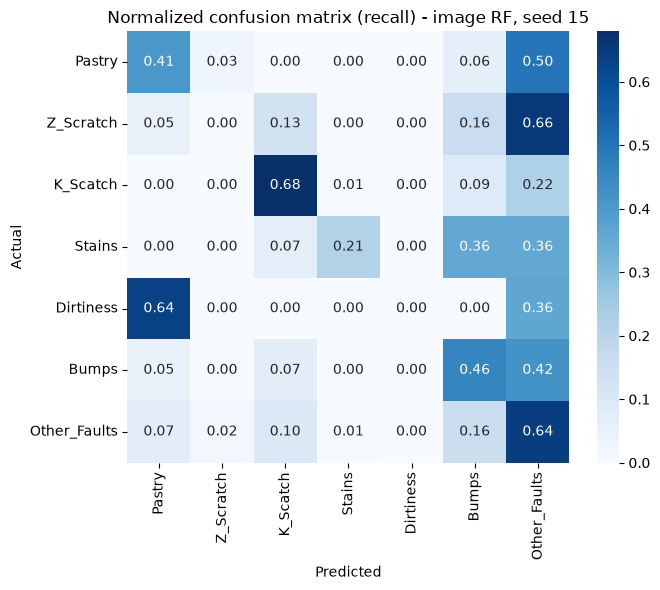

In [9]:
X = X_by_seed[best_seed]
model = make_model().fit(X[is_train], y_train)
y_pred = model.predict(X[~is_train])

print(f"Best seed {best_seed}  test Macro F1 {f1_score(y_test, y_pred, average='macro'):.4f}"
      f"  /  accuracy {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, digits=3))

cm = confusion_matrix(y_test, y_pred, labels=FAULTS, normalize="true")
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=FAULTS, yticklabels=FAULTS)
plt.title(f"Normalized confusion matrix (recall) - image RF, seed {best_seed}")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## 8. 참고 — 모든 seed의 test 점수 (선택에 쓰지 않음)

**궁금증 확인용**이다. 여기 점수를 보고 seed를 다시 고르면 test가 검증 데이터가 되어 버린다.

- CV 1등 seed가 test에서도 1등인지
- CV 점수와 test 점수가 같이 움직이는지 (상관)
- seed 평균 앙상블(seed마다 학습한 모델의 확률 평균)은 어떤지

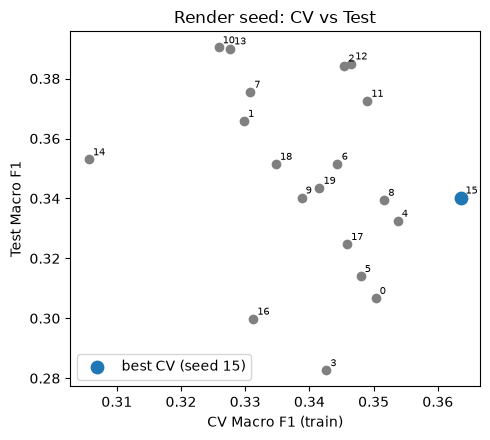

CV-test 상관:              -0.284
CV 1등 seed 15의 test 순위: 13 / 20
test 점수 seed 평균:        0.3472 ± 0.0311
seed 20개 앙상블 test:     0.3181


,cv_accuracy,cv_f1_macro,test_f1_macro
seed,,,
15,0.5039,0.3637,0.3402
4,0.4890,0.3537,0.3325
8,0.5084,0.3516,0.3395
0,0.4981,0.3503,0.3067
11,0.5019,0.3490,0.3725
5,0.5174,0.3480,0.3141
12,0.5090,0.3465,0.3850
17,0.4994,0.3459,0.3247
2,0.4936,0.3454,0.3843


In [10]:
test_rows, proba_sum = [], 0
for seed in SEEDS:
    X = X_by_seed[seed]
    m = make_model().fit(X[is_train], y_train)
    proba = m.predict_proba(X[~is_train])
    proba_sum = proba_sum + proba
    test_rows.append({"seed": seed,
                      "test_f1_macro": f1_score(y_test, m.classes_[proba.argmax(axis=1)], average="macro")})

ref = cv_result.join(pd.DataFrame(test_rows).set_index("seed"))
ens_test_f1 = f1_score(y_test, CLASSES[proba_sum.argmax(axis=1)], average="macro")

plt.figure(figsize=(5, 4.5))
plt.scatter(ref["cv_f1_macro"], ref["test_f1_macro"], color="gray")
plt.scatter(ref.loc[best_seed, "cv_f1_macro"], ref.loc[best_seed, "test_f1_macro"], color="tab:blue",
            s=80, label=f"best CV (seed {best_seed})")
for s, r in ref.iterrows():
    plt.annotate(s, (r.cv_f1_macro, r.test_f1_macro), fontsize=7, xytext=(3, 3), textcoords="offset points")
plt.xlabel("CV Macro F1 (train)"); plt.ylabel("Test Macro F1")
plt.title("Render seed: CV vs Test")
plt.legend()
plt.tight_layout()
plt.show()

print(f"CV-test 상관:              {ref['cv_f1_macro'].corr(ref['test_f1_macro']):.3f}")
print(f"CV 1등 seed {best_seed}의 test 순위: {int(ref['test_f1_macro'].rank(ascending=False)[best_seed])} / {len(ref)}")
print(f"test 점수 seed 평균:        {ref['test_f1_macro'].mean():.4f} ± {ref['test_f1_macro'].std():.4f}")
print(f"seed {len(SEEDS)}개 앙상블 test:     {ens_test_f1:.4f}")
ref.sort_values("cv_f1_macro", ascending=False).round(4)

## 9. 정리

처음 작성할 때 실행한 결과 (seed 0~19, RF 300 trees, 32×32 이미지만 사용):

| 항목 | Macro F1 |
|---|---|
| train CV, seed 20개 평균 | 0.340 ± 0.013 |
| train CV, best seed 15 | 0.364 (20개 중 최댓값이라 부풀려진 값) |
| **test, best seed 15 (보고용)** | **0.340** |
| 참고: test, seed 20개 평균 | 0.347 ± 0.031 |
| 참고: test, seed 20개 앙상블 | 0.318 |
| 비교: 원본 27개 특성 RF (baseline, CV) | 0.79 |

- **CV 1등 seed가 test에서는 20개 중 13등**이었다. CV와 test 점수의 상관은 -0.28로, seed 사이의 차이는 실력이 아니라 노이즈다.
- best seed의 test 점수(0.340)는 seed 평균(0.347)과 다르지 않다. seed를 고른 효과는 없었다.
- test 점수의 seed 간 표준편차(0.031)가 CV(0.013)보다 큰 것은 test가 작아서(389개, Dirtiness 11개) 흔들림이 크기 때문이다.
- 이미지만으로는 **Dirtiness, Z_Scratch를 하나도 못 맞췄다.** 두 클래스는 모양보다 크기·밝기·위치 같은, 이미지에 없는 정보로 구분되는 것으로 보인다.
- 3번 표처럼 seed에 따라 fill이 목표보다 0.02~0.04 낮게 나오는 경우가 있다. 무작위 모양에서는 `p`만으로 넓이를 완전히 맞추지 못할 때가 있다.

> 결론: 무작위 렌더링 seed는 고르는 대상이 아니다. 이미지 기반 분류는 원본 특성 모델보다 크게 낮다.